# Classificazione del diabete con i CDC Diabetes Health Indicators

## Progetto d'esame - Apprendimento Automatico e Apprendimento Profondo**

### Studente: Elia Valenza
### Matricola: 0322600066

# Introduzione e obiettivi

In uno screening, individuare precocemente le persone a rischio di diabete
permette di decidere a chi proporre esami di conferma. Qui il costo degli
errori è **asimmetrico**: non riconoscere un malato (**falso negativo**) è più
grave che inviare una persona sana a un approfondimento (**falso positivo**).

Questo lavoro affronta il problema come una **classificazione binaria** sul
dataset CDC Diabetes Health Indicators, che raccoglie le risposte di
253.680 adulti statunitensi a un questionario sanitario (BRFSS 2015) e
indica se hanno il diabete. Comprende:

- l'analisi delle feature con la **PCA**;
- il confronto di **tre classificatori** (regressione logistica, Random Forest
  e XGBoost), con iperparametri scelti per cross-validation;
- la valutazione con precision, recall, F-measure, accuracy, ROC AUC e
   matrice di confusione su un test set non usato per nessuna scelta;
- la **spiegabilità** delle previsioni con SHAP.

Particolare attenzione è dedicata alla **correttezza della valutazione**: i
dati sono suddivisi in modo **stratificato** e **per gruppi di profili**
identici, perché lo stesso profilo non compaia sia nel training sia nel
test, e la **soglia di decisione** è scelta sul validation set per tenere
conto dello sbilanciamento tra le classi.

Il documento si chiude con discussione, limiti e conclusioni.

# Impostazione dell'ambiente

Le scelte che influenzano la riproducibilità sono concentrate qui: seed
globale, percorsi e parametri generali.

In [2]:
import random
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Riproducibilità ---------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

CWD = Path.cwd()
ROOT = CWD.parent if CWD.name == "Doc" else CWD
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "Doc" / "figure"
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- Dataset -----------------------------------------------------------
DATA_URL = "https://archive.ics.uci.edu/static/public/891/data.csv"
DATA_FILE = DATA_DIR / "cdc_diabetes_health_indicators.csv"
TARGET = "Diabetes_binary"
N_ROWS_EXPECTED = 253_680  # righe dichiarate da UCI

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# Dataset

## Scelta del dataset

Il dataset scelto è **CDC Diabetes Health Indicators** (UCI Machine
Learning Repository, id 891). Contiene le risposte di 253.680 adulti
statunitensi a un questionario sanitario, e il compito è classificare chi
ha ricevuto una diagnosi di diabete.


I dati provengono dal **Behavioral Risk Factor Surveillance System
(BRFSS)**, il sondaggio telefonico sulla salute condotto ogni anno dal CDC
statunitense. Il file distribuito da UCI è la versione ripulita e resa
pubblica su Kaggle da un autore terzo, a partire dal **BRFSS 2015**: dalle
441.455 risposte originali sono state tenute le 253.680 senza valori
mancanti o risposte "non so / rifiuto", conservando **21 variabili**
(Shechter e Shomron, 2026).


In [3]:
def load_data(path=DATA_FILE, url=DATA_URL):
    """Scarica il CSV da UCI se assente e ne verifica l'integrità."""
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    df = pd.read_csv(path)
    if len(df) != N_ROWS_EXPECTED:
        path.unlink()
        raise RuntimeError(
            f"Righe lette: {len(df)}, attese: {N_ROWS_EXPECTED}. "
            "Rilanciare la cella."
        )
    return df


df_raw = load_data()
df = df_raw.drop(columns="ID")  # ID è solo l'indice di riga
FEATURES = [c for c in df.columns if c != TARGET]

print(f"Righe: {len(df):,} | Feature: {len(FEATURES)} | "
      f"Mancanti: {int(df.isna().sum().sum())}")
df.head(3).T

Righe: 253,680 | Feature: 21 | Mancanti: 0


,0,1,2
Diabetes_binary,0,0,0
HighBP,1,0,1
HighChol,1,0,1
CholCheck,1,0,1
BMI,40,25,28
Smoker,1,1,0
Stroke,0,0,0
HeartDiseaseorAttack,0,0,0
PhysActivity,0,1,0
Fruits,0,0,1


## Descrizione delle variabili

Il file contiene **21 feature** e il target `Diabetes_binary`. Le etichette
dei livelli delle variabili ordinali non sono nel file: sono riportate
nella documentazione UCI, che rimanda al **codebook BRFSS**.

| Variabile | Tipo | Valori | Significato |
|:-------------------|:---------|:------|:---------------------------------|
| `HighBP` | binaria | 0/1 | Ipertensione diagnosticata |
| `HighChol` | binaria | 0/1 | Colesterolo alto diagnosticato |
| `CholCheck` | binaria | 0/1 | Controllo del colesterolo negli ultimi 5 anni |
| `BMI` | numerica | 12-98 | Indice di massa corporea (da peso e altezza dichiarati) |
| `Smoker` | binaria | 0/1 | Almeno 100 sigarette fumate nella vita |
| `Stroke` | binaria | 0/1 | Ictus pregresso |
| `HeartDiseaseorAttack` | binaria | 0/1 | Cardiopatia coronarica o infarto |
| `PhysActivity` | binaria | 0/1 | Attività fisica nell'ultimo mese, escluso il lavoro |
| `Fruits` | binaria | 0/1 | Consuma frutta almeno una volta al giorno |
| `Veggies` | binaria | 0/1 | Consuma verdura almeno una volta al giorno |
| `HvyAlcoholConsump` | binaria | 0/1 | Consumo forte di alcol |
| `AnyHealthcare` | binaria | 0/1 | Ha una copertura sanitaria |
| `NoDocbcCost` | binaria | 0/1 | Ha rinunciato al medico per motivi di costo (ultimi 12 mesi) |
| `GenHlth` | ordinale | 1-5 | Salute generale auto-valutata: 1 eccellente, 5 scarsa |
| `MentHlth` | conteggio | 0-30 | Giorni di cattiva salute mentale nell'ultimo mese |
| `PhysHlth` | conteggio | 0-30 | Giorni di cattiva salute fisica nell'ultimo mese |
| `DiffWalk` | binaria | 0/1 | Seria difficoltà a camminare o salire le scale |
| `Sex` | binaria | 0/1 | 0 femmina, 1 maschio |
| `Age` | ordinale | 1-13 | Classi di età di 5 anni: 1 = 18-24, 2 = 25-29, ..., 13 = 80 o più |
| `Education` | ordinale | 1-6 | Titolo di studio: 1 = nessuno, ..., 6 = laurea |
| `Income` | ordinale | 1-8 | Reddito annuo: 1 = meno di 10.000 $, ..., 8 = 75.000 $ o più |

Le feature non sono tutte dello stesso tipo, e questo condizionerà le
scelte successive. Il codice seguente classifica le variabili e ne
verifica intervalli e numero di valori distinti direttamente sui dati.

In [4]:
BINARY = [c for c in FEATURES if df[c].nunique() == 2]
ORDINAL = ["GenHlth", "Age", "Education", "Income"]
COUNT = ["MentHlth", "PhysHlth"]
NUMERIC = ["BMI"]

# Controllo: ogni feature appartiene a uno e un solo tipo
groups = [BINARY, ORDINAL, COUNT, NUMERIC]
assert sorted(sum(groups, [])) == sorted(FEATURES)

kind = {c: t for t, cols in zip(
    ["binaria", "ordinale", "conteggio", "numerica"], groups)
    for c in cols}
summary = pd.DataFrame({
    "Tipo": pd.Series(kind),
    "Distinti": df[FEATURES].nunique(),
    "Min": df[FEATURES].min(),
    "Max": df[FEATURES].max(),
    "Media": df[FEATURES].mean().round(2),
}).loc[FEATURES]
summary

,Tipo,Distinti,Min,Max,Media
HighBP,binaria,2,0,1,0.43
HighChol,binaria,2,0,1,0.42
CholCheck,binaria,2,0,1,0.96
BMI,numerica,84,12,98,28.38
Smoker,binaria,2,0,1,0.44
Stroke,binaria,2,0,1,0.04
HeartDiseaseorAttack,binaria,2,0,1,0.09
PhysActivity,binaria,2,0,1,0.76
Fruits,binaria,2,0,1,0.63
Veggies,binaria,2,0,1,0.81


Il quadro è quello di un questionario: **14 variabili binarie**, 4
ordinali con pochi livelli, **2 conteggi di giorni** (0-30) e una sola
variabile quasi continua, il BMI. Tutti i valori sono interi. Nessuna
variabile ha **valori mancanti**. Le conseguenze pratiche sono due: la PCA, che
lavora su varianza e correlazioni lineari, avrà poco da riassumere con
variabili binarie; e le variabili ordinali (`Age`, `Education`, `Income`,
`GenHlth`) codificate come interi vengono trattate come numeri
**equidistanti**, assunzione che discuteremo.

## Variabile target

`Diabetes_binary` vale 0 per "nessun diabete" e 1 per "diabete". La
documentazione UCI la descrive come "prediabete o diabete", ma non spiega
come sia stato codificato il prediabete, che nel questionario è una
risposta distinta e che in altre versioni del dataset costituisce una
classe a sé: non si può escludere che i **prediabetici** siano compresi
nella classe 0. Non è verificabile sui dati, perché UCI distribuisce solo
la versione binaria; lo trattiamo come un'**incertezza** e lo riprendiamo
tra i limiti.

## Distribuzione del target

            Classe  Righe  Percentuale
0 (nessun diabete) 218334        86.07
       1 (diabete)  35346        13.93

Rapporto negativi/positivi: 6.18 : 1
Accuracy di chi predice sempre 'nessun diabete': 0.8607


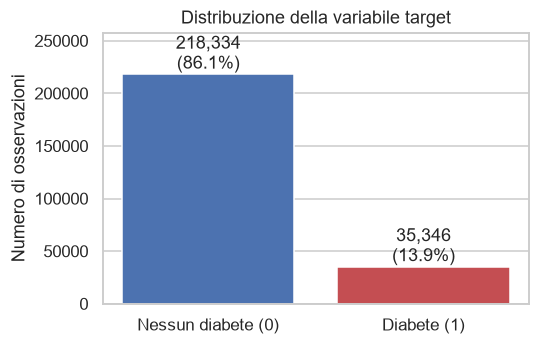

In [5]:
counts = df[TARGET].value_counts().sort_index()
prevalence = df[TARGET].mean()
majority_acc = 1 - prevalence

target_table = pd.DataFrame({
    "Classe": ["0 (nessun diabete)", "1 (diabete)"],
    "Righe": counts.values,
    "Percentuale": (counts / len(df) * 100).round(2).values,
})
print(target_table.to_string(index=False))
print(f"\nRapporto negativi/positivi: {counts[0] / counts[1]:.2f} : 1")
print(f"Accuracy di chi predice sempre 'nessun diabete': "
      f"{majority_acc:.4f}")

fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar(["Nessun diabete (0)", "Diabete (1)"], counts.values,
              color=["#4C72B0", "#C44E52"])
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n,
            f"{n:,}\n({n / len(df):.1%})", ha="center", va="bottom")
ax.set_ylabel("Numero di osservazioni")
ax.set_ylim(0, counts.max() * 1.18)
ax.set_title("Distribuzione della variabile target")
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "target_distribution.png", dpi=200,
            bbox_inches="tight")
plt.show()

Il dataset è **sbilanciato**: i positivi sono il **13,93%** (rapporto di circa
6 a 1). Ne derivano conseguenze che guidano il resto del progetto:

- un classificatore che risponde sempre "nessun diabete" ottiene
  un'accuracy dell'**86,07%** senza imparare nulla, quindi l'**accuracy da sola
  non è un criterio di confronto**;
- servono metriche che guardino alla **classe positiva** (precision, recall,
  F-measure) e metriche indipendenti dalla soglia (**ROC AUC**);
- lo split in train, validation e test deve essere **stratificato**, per
  mantenere la stessa proporzione di positivi in ogni insieme;
- la **soglia di decisione** andrà scelta in modo esplicito. Un modello
  restituisce la probabilità che una persona abbia il diabete, e la
  soglia è il valore oltre il quale la classifichiamo come positiva. Il
  valore di default, 0,5, è pensato per classi bilanciate: con solo il
  14% di positivi molti malati ricevono probabilità inferiori a 0,5 e
  vengono classificati come sani, per cui la recall risulta bassa.
  Abbassare la soglia permette di individuare più malati (recall più
  alta) al prezzo di più falsi positivi (precision più bassa). In uno
  screening mancare un malato è più grave che inviare una persona sana
  a un approfondimento, quindi la soglia verrà scelta sul validation
  set secondo un criterio dichiarato e non fissata a priori.

# Analisi esplorativa dei dati

L'analisi esplorativa ha lo scopo di **orientare le scelte successive**:
quali trasformazioni applicare alle variabili, quali usare nella PCA e
come suddividere i dati senza introdurre distorsioni nella valutazione.

## Distribuzione delle feature

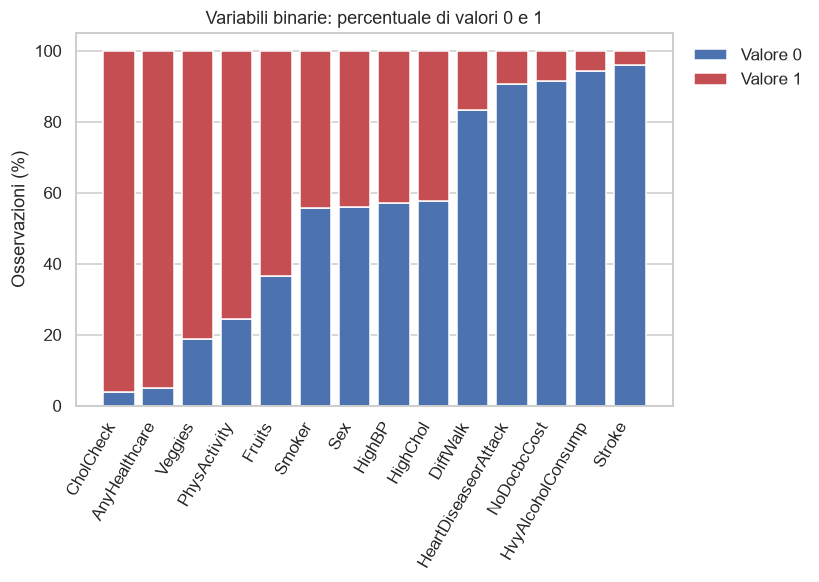

                      % valore 0  % valore 1
CholCheck                   3.73       96.27
AnyHealthcare               4.89       95.11
Veggies                    18.86       81.14
PhysActivity               24.35       75.65
Fruits                     36.57       63.43
Smoker                     55.68       44.32
Sex                        55.97       44.03
HighBP                     57.10       42.90
HighChol                   57.59       42.41
DiffWalk                   83.18       16.82
HeartDiseaseorAttack       90.58        9.42
NoDocbcCost                91.58        8.42
HvyAlcoholConsump          94.38        5.62
Stroke                     95.94        4.06

Sulle 14 variabili binarie: 45.0% di valori 1 e 55.0% di valori 0
Valori 1 per osservazione: media 6.30, mediana 6 su 14
Variabili con categoria minoritaria sotto il 10%: 6 su 14
Valori nulli sull'intera matrice delle 21 feature: 43.0%


In [6]:
share_one = (df[BINARY].mean() * 100).sort_values(ascending=False)
share_zero = 100 - share_one

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.bar(share_one.index, share_zero, color="#4C72B0", label="Valore 0")
ax.bar(share_one.index, share_one, bottom=share_zero, color="#C44E52",
       label="Valore 1")
ax.set_ylabel("Osservazioni (%)")
ax.set_title("Variabili binarie: percentuale di valori 0 e 1")
ax.tick_params(axis="x", labelrotation=60)
plt.setp(ax.get_xticklabels(), ha="right")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "binary_frequency.png", dpi=200, bbox_inches="tight")
plt.show()

summary_bin = pd.DataFrame({"% valore 0": share_zero,
                            "% valore 1": share_one}).round(2)
print(summary_bin.to_string())

B = df[BINARY].to_numpy()
ones_per_row = B.sum(axis=1)
minority = np.minimum(share_one, share_zero)
print(f"\nSulle {len(BINARY)} variabili binarie: {B.mean():.1%} di valori 1 "
      f"e {1 - B.mean():.1%} di valori 0")
print(f"Valori 1 per osservazione: media {ones_per_row.mean():.2f}, "
      f"mediana {np.median(ones_per_row):.0f} su {len(BINARY)}")
print(f"Variabili con categoria minoritaria sotto il 10%: "
      f"{(minority < 10).sum()} su {len(BINARY)}")
print(f"Valori nulli sull'intera matrice delle {len(FEATURES)} feature: "
      f"{(df[FEATURES].to_numpy() == 0).mean():.1%}")

In [7]:
print(f"MentHlth = 0: {(df.MentHlth == 0).mean():.1%} | "
      f"PhysHlth = 0: {(df.PhysHlth == 0).mean():.1%}")
print("BMI, percentili 1-25-50-75-99:",
      df.BMI.quantile([.01, .25, .5, .75, .99]).tolist())
print(f"BMI > 60: {(df.BMI > 60).mean():.2%} (massimo {df.BMI.max()})")

MentHlth = 0: 69.3% | PhysHlth = 0: 63.1%
BMI, percentili 1-25-50-75-99: [18.0, 24.0, 27.0, 31.0, 50.0]
BMI > 60: 0.32% (massimo 98)


La matrice dei dati **non è sparsa**: nelle 14 variabili binarie il 45% dei
valori è 1 e il 55% è 0, e ogni osservazione ha in media 6,3 valori 1 su
14. Considerando tutte le 21 feature i valori nulli sono il 43%, in
gran parte dovuti alle binarie e ai due conteggi di giorni, per cui non
servono trattamenti specifici per dati sparsi. Le singole variabili sono
però molto diverse tra loro: 6 su 14 hanno una categoria minoritaria
sotto il 10%. `CholCheck` (96%) e `AnyHealthcare` (95%) sono quasi
costanti, mentre `Stroke` (4%), `HvyAlcoholConsump` (6%),
`NoDocbcCost` (8%) e `HeartDiseaseorAttack` (9%) descrivono condizioni
rare. I due conteggi di giorni sono **molto asimmetrici**: il 69% delle
persone dichiara 0 giorni di cattiva salute mentale e il 63% 0 giorni di
cattiva salute fisica. Il BMI ha una
distribuzione con **coda a destra** (mediana 27, 99° percentile 50) e lo 0,3%
delle osservazioni supera 60, fino a un massimo di 98.

Il BMI deriva da peso e altezza dichiarati, quindi non è possibile
distinguere errori di compilazione da valori estremi reali. I valori
anomali **non vengono eliminati**: riguardano solo lo 0,3% delle
osservazioni, e due dei tre modelli usati (Random Forest e XGBoost) non
sono sensibili ai valori estremi.

## Correlazioni tra le feature

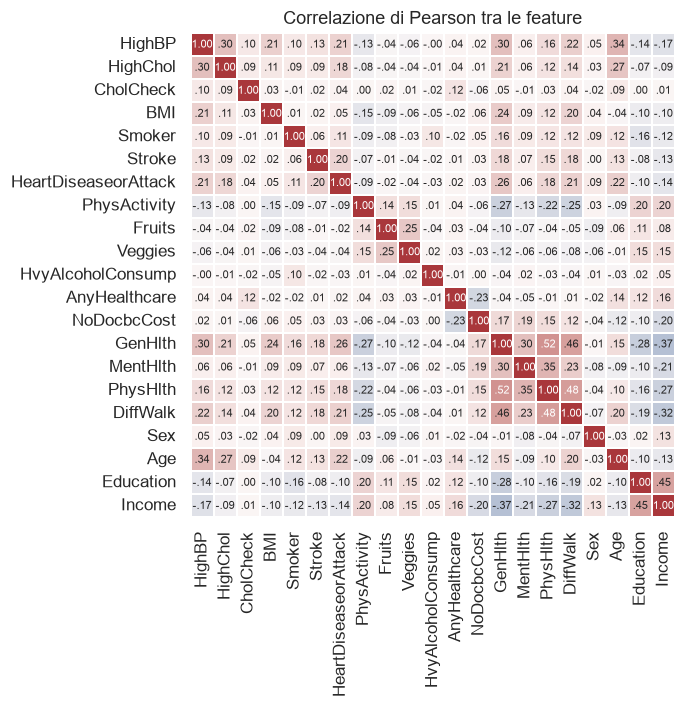

Coppie più correlate:
GenHlth    PhysHlth    0.52
PhysHlth   DiffWalk    0.48
GenHlth    DiffWalk    0.46
Education  Income      0.45
GenHlth    Income     -0.37
MentHlth   PhysHlth    0.35

Coppie con |r| > 0,4: 4 su 210 | con |r| > 0,3: 10


In [7]:
corr = df[FEATURES].corr()

labels = corr.map(lambda v: f"{v:.2f}".replace("0.", "."))
fig, ax = plt.subplots(figsize=(7.2, 6.6))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            annot=labels, fmt="", annot_kws={"size": 7.5},
            linewidths=0.3, cbar=False, ax=ax)
ax.set_title("Correlazione di Pearson tra le feature")
fig.tight_layout()
fig.savefig(FIG_DIR / "feature_correlation.png", dpi=200)
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
pairs = pairs.dropna()
top = pairs.reindex(pairs.abs().sort_values(ascending=False).index)[:6]
print("Coppie più correlate:")
print(top.round(2).to_string())
print(f"\nCoppie con |r| > 0,4: {(pairs.abs() > 0.4).sum()} su {len(pairs)}"
      f" | con |r| > 0,3: {(pairs.abs() > 0.3).sum()}")

Le feature sono per lo più **debolmente correlate** tra loro: solo 4 coppie su
210 superano |r| = 0,4 e 10 superano 0,3. Le correlazioni più alte
riguardano lo **stato di salute** (`GenHlth`-`PhysHlth` 0,52,
`PhysHlth`-`DiffWalk` 0,48, `GenHlth`-`DiffWalk` 0,46) e la condizione
**socioeconomica** (`Education`-`Income` 0,45). Il coefficiente di Pearson è
solo indicativo per variabili binarie e ordinali, ma il quadro suggerisce
che l'informazione sia **distribuita su molte dimensioni** e che la PCA possa
comprimerla poco: lo verificheremo nella sezione dedicata.

## Duplicati e profili

Chiamiamo **profilo** l'insieme dei valori delle 21 feature. Con variabili
quasi tutte binarie od ordinali i profili possibili sono relativamente
pochi, e **persone diverse con le stesse risposte** sono attese.

In [9]:
PROFILE = df.groupby(FEATURES).ngroup()  # identificativo del profilo
repeated_row = PROFILE.duplicated()      # riga che ripete un profilo già visto

by_profile = df.groupby(PROFILE)[TARGET].agg(["size", "nunique"])
conflicting = by_profile[by_profile["nunique"] > 1]

print(f"Profili distinti: {PROFILE.nunique():,}")
print(f"Righe che ripetono un profilo: {repeated_row.sum():,} "
      f"({repeated_row.mean():.2%})")
print("Quota di righe ripetute per classe:",
      repeated_row.groupby(df[TARGET]).mean().round(4).to_dict())
print(f"Profili con etichette discordanti: {len(conflicting):,} "
      f"({conflicting['size'].sum():,} righe)")

Profili distinti: 227,908
Righe che ripetono un profilo: 25,772 (10.16%)
Quota di righe ripetute per classe: {0: 0.1127, 1: 0.033}
Profili con etichette discordanti: 1,566 (5,218 righe)


Il file contiene **227.908 profili distinti** e **25.772 righe (10,2%)** che ne
ripetono uno già presente. Le ripetizioni sono molto più frequenti tra i
negativi (11,3%) che tra i positivi (3,3%): sono profili comuni di persone
senza diabete. In **1.566 profili (5.218 righe)** le etichette sono
**discordanti**: a parità di risposte l'esito cambia, quindi il questionario
non determina completamente la diagnosi. È una fonte di errore
**irriducibile** che limita le prestazioni ottenibili da qualunque modello.

Il rischio per la valutazione è il **leakage**: se lo stesso profilo
compare sia nel training sia nel test, il modello lo ha già visto e le
metriche risultano ottimistiche.

Gli studi precedenti su dati BRFSS non trattano esplicitamente i
profili ripetuti, e differiscono per il modo in cui suddividono e
ricampionano i dati. **Xie et al. (2019)**, che sui dati BRFSS 2014 ottengono
un'accuracy tra 0,74 e 0,82 e un'AUC tra 0,72 e 0,79, usano un singolo
**hold-out** (due terzi per il training, un terzo per il test), applicano
il **SMOTE** al training e valutano su un test con la distribuzione
originale. **Ullah et al. (2022)**, che riportano un'accuracy del 98% con il
KNN, bilanciano le classi con **SMOTE-ENN** e usano un singolo split 70/30,
senza specificare se il ricampionamento sia avvenuto prima o dopo la
suddivisione e senza mostrare risultati sui dati non ricampionati. In
nessuno dei due casi è dichiarato come siano trattati i profili
identici, che possono quindi comparire sia nel training sia nel test.

Noi abbiamo scelto di **non eliminare dati**: le ripetizioni sono
osservazioni reali e portano informazione sulla frequenza dei profili.
Per evitare il leakage suddividiamo invece i dati **per gruppi**: tutte
le righe di uno stesso profilo vengono assegnate allo stesso insieme
(training, validation o test), così nessun profilo compare in più di un
insieme. La suddivisione, stratificata sul target, è descritta nella
sezione successiva.

# Suddivisione dei dati

I dati sono divisi in tre insiemi con proporzioni **70/15/15**:

- **training** (70%): addestramento dei modelli e ricerca degli
  iperparametri con cross-validation;
- **validation** (15%): confronto tra i modelli e scelta della soglia di
  decisione;
- **test** (15%): valutazione finale, usato una sola volta.

Con 253.680 osservazioni il 15% corrisponde a circa 38.000 righe e a circa
5.300 positivi per insieme: abbastanza per stimare le metriche sulla
classe positiva con un **errore standard inferiore a un punto percentuale**.

La suddivisione rispetta i due vincoli discussi in precedenza: è
**stratificata** sul target, per avere in ogni insieme la stessa
prevalenza di diabete, ed è **per gruppi di profilo**, per evitare il
leakage. Si usa `StratifiedGroupKFold` con 20 blocchi di circa il 5%: tre
vanno al test, tre al validation e quattordici al training. Il seed è
fisso, così tutti i modelli usano gli stessi insiemi.

In [10]:
from sklearn.model_selection import StratifiedGroupKFold

N_FOLDS = 20  # blocchi da circa il 5%: 3 test, 3 validation, 14 training
splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True,
                                random_state=SEED)
fold = np.empty(len(df), dtype=int)
for k, (_, idx) in enumerate(splitter.split(df[FEATURES], df[TARGET],
                                            groups=PROFILE)):
    fold[idx] = k

subset = pd.Series(
    np.select([fold < 3, fold < 6], ["test", "validation"], default="train"),
    index=df.index)

X, y = df[FEATURES], df[TARGET]
X_train, y_train = X[subset == "train"], y[subset == "train"]
X_val, y_val = X[subset == "validation"], y[subset == "validation"]
X_test, y_test = X[subset == "test"], y[subset == "test"]
groups_train = PROFILE[subset == "train"]  # gruppi per la cross-validation

rows = []
for name, key in {"Training": "train", "Validation": "validation",
                  "Test": "test"}.items():
    m = subset == key
    rows.append({"Insieme": name, "Righe": m.sum(),
                 "Quota": f"{m.mean():.1%}", "Positivi": int(y[m].sum()),
                 "Prevalenza": f"{y[m].mean():.2%}",
                 "Profili": PROFILE[m].nunique()})
print(pd.DataFrame(rows).set_index("Insieme").to_string())

pairs = [("train", "validation"), ("train", "test"), ("validation", "test")]
shared = [len(set(PROFILE[subset == a]) & set(PROFILE[subset == b]))
          for a, b in pairs]
assert shared == [0, 0, 0]
print("\nProfili in comune (train-validation, train-test, "
      f"validation-test): {shared}")

             Righe  Quota  Positivi Prevalenza  Profili
Insieme                                                
Training    177575  70.0%     24741     13.93%   159569
Validation   38051  15.0%      5302     13.93%    34163
Test         38054  15.0%      5303     13.94%    34176

Profili in comune (train-validation, train-test, validation-test): [0, 0, 0]


I tre insiemi contengono 177.575, 38.051 e 38.054 righe (70,0%, 15,0% e
15,0%), con una prevalenza del diabete praticamente identica (13,93%,
13,93% e 13,94%) e **nessun profilo in comune**. Modelli, iperparametri e
soglia saranno scelti **senza usare il test**, e la cross-validation sul
training userà gli stessi gruppi di profilo, per evitare il leakage anche
al suo interno.

# Analisi delle feature con PCA

La **PCA (Principal Component Analysis)** trasforma le feature in componenti
principali non correlate, ordinate per **varianza spiegata**. La applichiamo
alle sole **variabili non binarie** (`BMI`, `GenHlth`, `MentHlth`, `PhysHlth`,
`Age`, `Education`, `Income`), che hanno una scala numerica: la PCA lavora
su varianza e correlazioni lineari, e su variabili binarie avrebbe poco da
riassumere. Le ordinali sono trattate come numeri. I classificatori
useranno comunque tutte le **feature originali**.

Le variabili vengono **standardizzate** (media 0 e varianza 1), così nessuna
prevale per la sua scala. Scaler e PCA sono adattati **solo sul
training**, per non usare informazioni di validation e test.

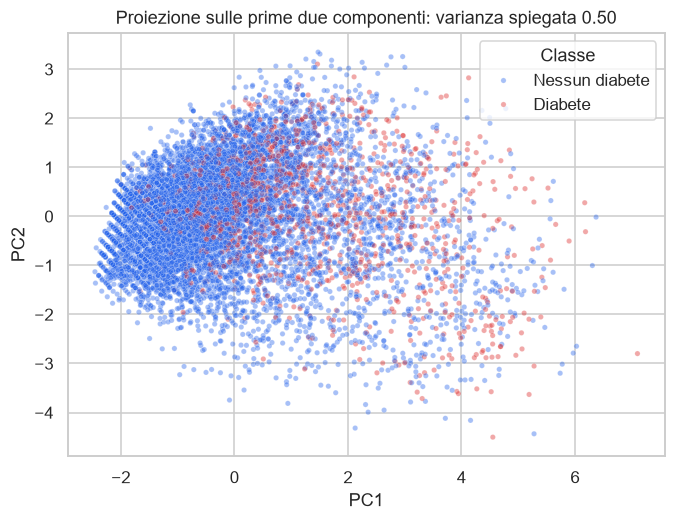

Varianza PC1: 33.23%
Varianza PC2: 16.55%
Varianza spiegata dalle prime due componenti: 49.78%


In [13]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

NON_BINARY = NUMERIC + COUNT + ORDINAL

scaler = StandardScaler().fit(X_train[NON_BINARY])
Z_train = scaler.transform(X_train[NON_BINARY])
pca = PCA().fit(Z_train)

variance = pca.explained_variance_ratio_
components = np.arange(1, len(variance) + 1)

# Proiezione sulle prime due componenti (campione di 10.000 per leggibilità)
rng = np.random.default_rng(SEED)
sample = rng.choice(len(Z_train), size=10_000, replace=False)
df_pca = pd.DataFrame(pca.transform(Z_train[sample])[:, :2],
                      columns=["PC1", "PC2"])
df_pca["Classe"] = np.where(y_train.to_numpy()[sample] == 1,
                            "Diabete", "Nessun diabete")

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="Classe",
                palette={"Nessun diabete": "#2563EB", "Diabete": "#DC2626"},
                s=12, alpha=0.4)
plt.title("Proiezione sulle prime due componenti: varianza spiegata "
          f"{variance[:2].sum():.2f}")
plt.savefig(FIG_DIR / "pca_projection.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Varianza PC1: {variance[0]:.2%}")
print(f"Varianza PC2: {variance[1]:.2%}")
print(f"Varianza spiegata dalle prime due componenti: "
      f"{variance[:2].sum():.2%}")

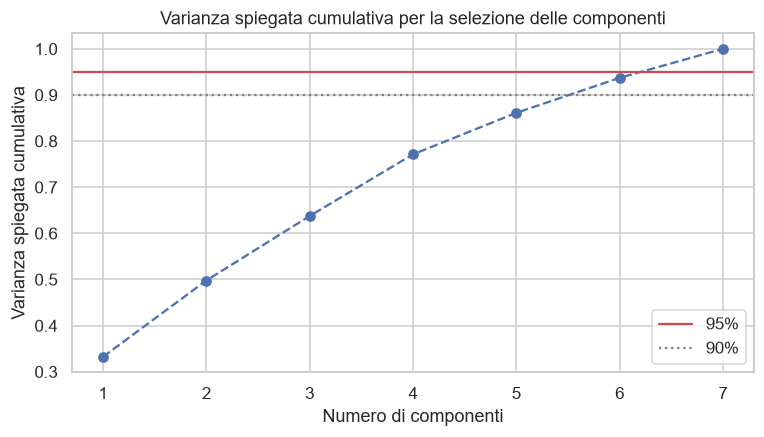

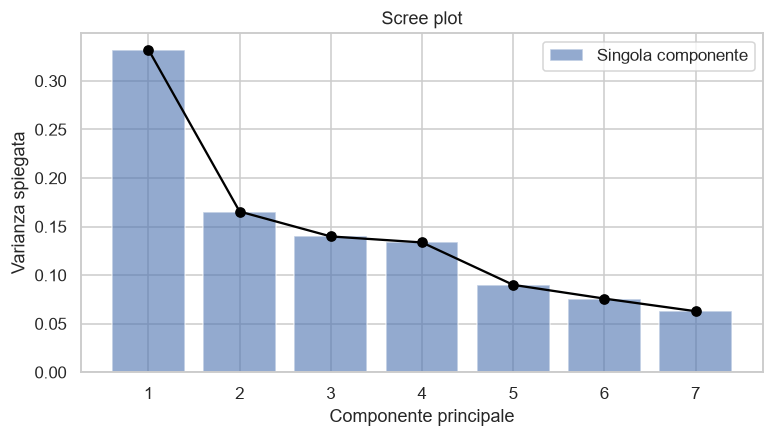

Componenti per spiegare il 90% e il 95% della varianza: 6 7
Varianza per componente (%): [33.2, 16.6, 14.0, 13.4, 9.0, 7.6, 6.3]


In [11]:
# Varianza spiegata cumulativa
plt.figure(figsize=(8, 4))
plt.plot(components, np.cumsum(variance), marker="o", linestyle="--")
plt.xticks(components)
plt.xlabel("Numero di componenti")
plt.ylabel("Varianza spiegata cumulativa")
plt.axhline(y=0.95, color="r", linestyle="-", label="95%")
plt.axhline(y=0.90, color="gray", linestyle=":", label="90%")
plt.title("Varianza spiegata cumulativa per la selezione delle componenti")
plt.legend(loc="lower right")
plt.savefig(FIG_DIR / "pca_cumulative.png", dpi=200, bbox_inches="tight")
plt.show()

# Scree plot: varianza spiegata da ogni singola componente
plt.figure(figsize=(8, 4))
plt.bar(components, variance, alpha=0.6, label="Singola componente")
plt.plot(components, variance, marker="o", color="black")
plt.xticks(components)
plt.xlabel("Componente principale")
plt.ylabel("Varianza spiegata")
plt.title("Scree plot")
plt.legend()
plt.savefig(FIG_DIR / "pca_scree.png", dpi=200, bbox_inches="tight")
plt.show()

cumulative = np.cumsum(variance)
print("Componenti per spiegare il 90% e il 95% della varianza:",
      int(np.searchsorted(cumulative, 0.90) + 1),
      int(np.searchsorted(cumulative, 0.95) + 1))
print("Varianza per componente (%):", (variance * 100).round(1).tolist())

In [12]:
loadings = pd.DataFrame(pca.components_[:2].T, index=NON_BINARY,
                        columns=["PC1", "PC2"]).round(2)
print("Pesi delle feature sulle prime due componenti:")
print(loadings.to_string())

Pesi delle feature sulle prime due componenti:
            PC1   PC2
BMI        0.22 -0.25
MentHlth   0.34 -0.49
PhysHlth   0.46 -0.23
GenHlth    0.52 -0.07
Age        0.13  0.63
Education -0.37 -0.40
Income    -0.45 -0.29


Le prime due componenti spiegano il **49,8% della varianza** (33,2% e
16,6%); ne servono 6 per arrivare al 90% e 7, cioè tutte, per il 95%. Lo
scree plot non mostra un **gomito netto**: dopo la prima componente le
varianze scendono gradualmente (16,6%, 14,0%, 13,4%, 9,0%, 7,6%, 6,3%).
Il criterio del 90-95% non è soddisfatto da poche componenti, quindi in
questo dataset la PCA non offre una **riduzione di dimensioni vantaggiosa**,
in linea con la correlazione moderata tra le variabili.

Nella proiezione i positivi si collocano prevalentemente su valori più
alti della PC1, ma le due classi si **sovrappongono molto**. La PC1 contrappone cattiva salute generale e fisica
(`GenHlth` 0,52, `PhysHlth` 0,46, `MentHlth` 0,34) a istruzione e reddito
elevati (`Income` -0,45, `Education` -0,37); la PC2 è dominata dall'età
(0,63) in opposizione a salute mentale, istruzione e reddito. Il diabete
si associa quindi soprattutto a un **asse di salute e condizione**
socioeconomica, ma due dimensioni non bastano a separare le classi.

# Classificatori

Confrontiamo tre algoritmi che rappresentano **famiglie diverse**:

- **regressione logistica**: modello lineare, interpretabile e veloce, usato
  come riferimento;
- **Random Forest**: insieme di alberi addestrati su campioni diversi dei
  dati (bagging), in grado di cogliere relazioni non lineari e interazioni;
- **XGBoost**: insieme di alberi costruiti in sequenza, ciascuno dei quali
  corregge gli errori dei precedenti (boosting).


## Ricerca degli iperparametri

Gli iperparametri sono scelti con una **GridSearch** sul solo training,
con **cross-validation a 5 blocchi** che rispetta stratificazione e gruppi di
profilo (`StratifiedGroupKFold`), per evitare il leakage anche dentro la
ricerca. Il criterio è la **ROC AUC**, che non dipende dalla soglia di
decisione e non è distorta dallo sbilanciamento delle classi, a differenza
dell'accuracy.

**Non applichiamo ricampionamenti né pesi sulle classi**: la ROC AUC dipende
solo da come il modello ordina le osservazioni, e lo sbilanciamento verrà
gestito scegliendo la soglia di decisione sul validation set. I modelli
sono addestrati sulle feature originali; la regressione logistica richiede
anche la standardizzazione, inserita in una pipeline.

Le griglie sono contenute, per limitare i tempi di calcolo:

- regressione logistica: intensità della regolarizzazione `C`;
- Random Forest: `max_depth` e `max_features`, con 300 alberi (più alberi
  riducono la varianza e non peggiorano il modello);
- XGBoost: `learning_rate`, `max_depth` e `reg_lambda`, con 300 alberi.

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

# Cross-validation a 5 blocchi, stratificata e per gruppi di profilo
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

# Regressione logistica (con standardizzazione delle feature)
pipe_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
param_grid_lr = {"logisticregression__C": [0.01, 0.1, 1, 10]}
grid_lr = GridSearchCV(pipe_lr, param_grid_lr, cv=cv, scoring="roc_auc",
                       refit=True)
grid_lr.fit(X_train, y_train, groups=groups_train)

# Random Forest
rf_base = RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                 random_state=SEED)
param_grid_rf = {"max_depth": [8, 12, 16],
                 "max_features": ["sqrt", 0.5]}
grid_rf = GridSearchCV(rf_base, param_grid_rf, cv=cv, scoring="roc_auc",
                       refit=True)
grid_rf.fit(X_train, y_train, groups=groups_train)

# XGBoost
xgb_base = XGBClassifier(n_estimators=300, tree_method="hist", n_jobs=-1,
                         random_state=SEED)
param_grid_xgb = {"learning_rate": [0.05, 0.1],
                  "max_depth": [3, 5],
                  "reg_lambda": [1, 10]}
grid_xgb = GridSearchCV(xgb_base, param_grid_xgb, cv=cv, scoring="roc_auc",
                        refit=True)
grid_xgb.fit(X_train, y_train, groups=groups_train)

# Modelli finali: con refit=True la ricerca riaddestra ciascun modello
# sull'intero training con i migliori iperparametri
best_models = {"Regressione logistica": grid_lr.best_estimator_,
               "Random Forest": grid_rf.best_estimator_,
               "XGBoost": grid_xgb.best_estimator_}

# Riepilogo dei risultati
grids = {"Regressione logistica": grid_lr, "Random Forest": grid_rf,
         "XGBoost": grid_xgb}
for name, grid in grids.items():
    std = grid.cv_results_["std_test_score"][grid.best_index_]
    params = ", ".join(f"{k.split('__')[-1]} = {v}"
                       for k, v in grid.best_params_.items())
    print(name)
    print(f"  migliori iperparametri: {params}")
    print(f"  AUC in cross-validation: {grid.best_score_:.4f} ± {std:.4f}")
    print()

Regressione logistica
  migliori iperparametri: C = 0.01
  AUC in cross-validation: 0.8225 ± 0.0016

Random Forest
  migliori iperparametri: max_depth = 12, max_features = sqrt
  AUC in cross-validation: 0.8268 ± 0.0011

XGBoost
  migliori iperparametri: learning_rate = 0.1, max_depth = 3, reg_lambda = 10
  AUC in cross-validation: 0.8307 ± 0.0012



La ricerca ha scelto, per la regressione logistica, `C` = 0,01
(regolarizzazione forte); per la Random Forest `max_depth` = 12 e
`max_features` = sqrt; per XGBoost `learning_rate` = 0,1, `max_depth` = 3
e `reg_lambda` = 10. Le **AUC in cross-validation** sono 0,8225 per la
regressione logistica, 0,8268 per la Random Forest e 0,8307 per XGBoost,
con deviazioni standard tra i blocchi di 0,001-0,002.

L'ordine dei modelli è quello atteso, ma **le differenze sono piccole**
(0,008 tra il primo e il terzo) e confrontabili con la variabilità tra
blocchi. Un modello lineare molto vicino ai modelli ad albero indica che
il segnale utile è **in buona parte lineare** e che l'informazione contenuta
nelle 21 feature è limitata, in accordo con i profili a etichette
discordanti discussi in precedenza. Alcuni iperparametri scelti sono ai
**bordi della griglia** (`C` minimo; per XGBoost `learning_rate` e
`reg_lambda` massimi e `max_depth` minimo): estendere la griglia potrebbe
migliorare ancora di poco i risultati, ma non è stato fatto per
contenere i tempi di calcolo.

# Metriche di valutazione

Le metriche sono calcolate sulla **classe positiva** (diabete):

- **precision**: tra le persone segnalate come a rischio, la quota che ha
  davvero il diabete;
- **recall**: tra le persone con diabete, la quota individuata dal modello;
- **F-measure**: media armonica di precision e recall;
- **accuracy**: quota di previsioni corrette, da leggere accanto
  all'86,07% di chi risponde sempre "nessun diabete";
- **ROC AUC**: capacità del modello di ordinare le persone per rischio,
  indipendente dalla soglia.

## Soglia di decisione

Le prime quattro metriche **dipendono dalla soglia**. In uno screening mancare
un malato **è più grave** che inviare una persona sana a un approfondimento,
quindi assumiamo una **recall minima dell'80%** e scegliamo, per ciascun
modello e sul validation set, la soglia più alta che la rispetta, cioè
quella con la precision migliore a quel livello di recall. In questo modo
i modelli si confrontano **a parità di malati individuati**.

In [14]:
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)

TARGET_RECALL = 0.80

proba_val = {name: model.predict_proba(X_val)[:, 1]
             for name, model in best_models.items()}


def threshold_for_recall(y_true, proba, target):
    _, recall, thresholds = precision_recall_curve(y_true, proba)
    return thresholds[np.where(recall[:-1] >= target)[0][-1]]


thresholds = {name: threshold_for_recall(y_val, proba, TARGET_RECALL)
              for name, proba in proba_val.items()}


def evaluate_at(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {"Soglia": threshold,
            "Precision": precision_score(y_true, pred),
            "Recall": recall_score(y_true, pred),
            "F-measure": f1_score(y_true, pred),
            "Accuracy": accuracy_score(y_true, pred),
            "ROC AUC": roc_auc_score(y_true, proba),
            "Segnalati": pred.mean()}


metrics_val = pd.DataFrame({name: evaluate_at(y_val, proba_val[name],
                                              thresholds[name])
                            for name in proba_val}).T
print(metrics_val.drop(columns="Segnalati").round(3).to_string())
print("Quota di persone segnalate:",
      metrics_val["Segnalati"].round(3).to_dict())

                       Soglia  Precision  Recall  F-measure  Accuracy  ROC AUC
Regressione logistica   0.124      0.294     0.8      0.430     0.705    0.820
Random Forest           0.142      0.300     0.8      0.437     0.712    0.826
XGBoost                 0.135      0.304     0.8      0.441     0.717    0.829
Quota di persone segnalate: {'Regressione logistica': 0.379, 'Random Forest': 0.371, 'XGBoost': 0.367}


A parità di recall (0,80 per costruzione), la precision è 0,294 per la
regressione logistica, 0,300 per la Random Forest e 0,304 per XGBoost:
tra le persone segnalate **circa 30 su 100** hanno davvero il diabete, contro
il 13,9% della popolazione. F-measure (0,430, 0,437 e 0,441) e ROC AUC
(0,820, 0,826 e 0,829) confermano l'ordine emerso in cross-validation, con
**XGBoost leggermente migliore**; le differenze sono comunque piccole.

L'accuracy, tra 0,705 e 0,717, è **inferiore all'86,07%** del classificatore
che risponde sempre "nessun diabete": è atteso, perché la soglia privilegia
la recall e viene segnalato oltre un terzo della popolazione. È un'ulteriore
conferma che **l'accuracy non è adatta a confrontare i modelli** in questo
problema. Modelli e soglie sono ora **fissati** e saranno applicati al test set
una sola volta.

# Matrice di confusione e curva ROC

Valutiamo ora i tre modelli sul **test set**, usato qui per la prima e
unica volta, **con le soglie scelte sul validation**. Per ciascun modello si
mostrano la **matrice di confusione** alla soglia scelta e la **curva ROC**, con il
punto che corrisponde a quella soglia.

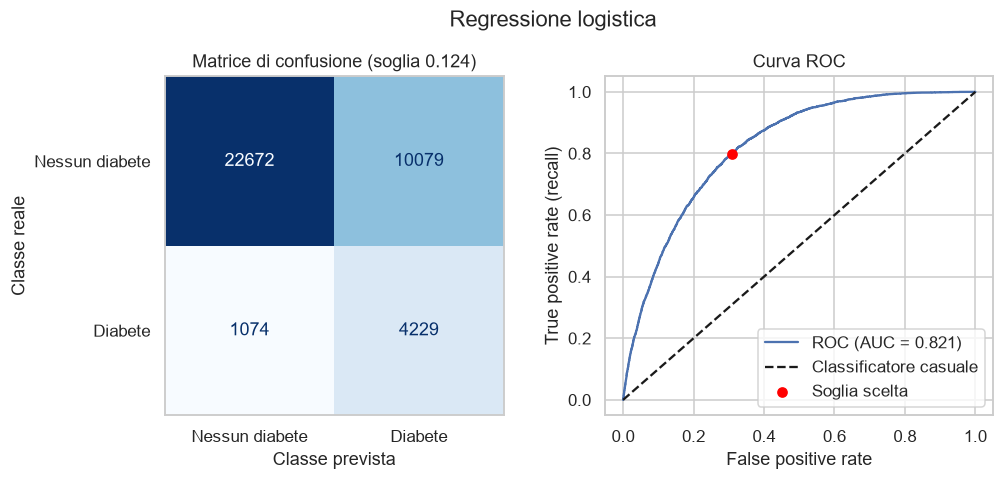

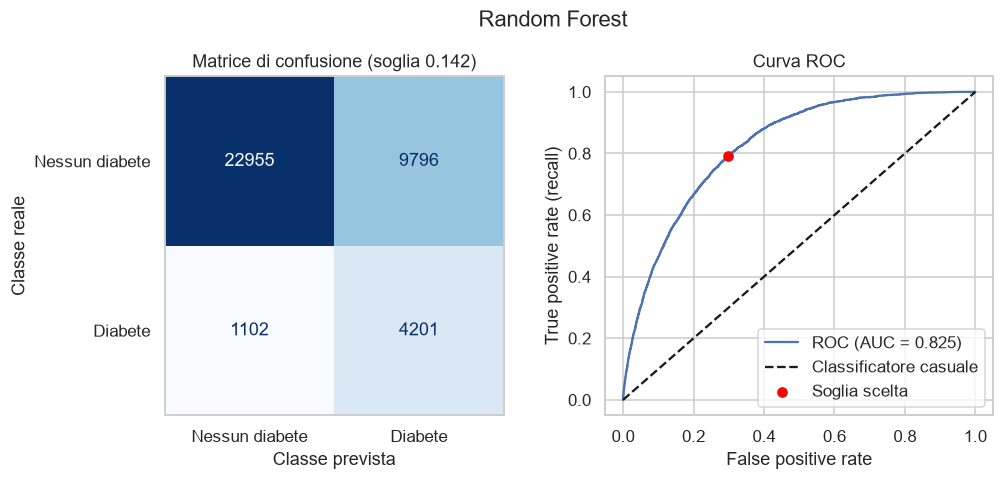

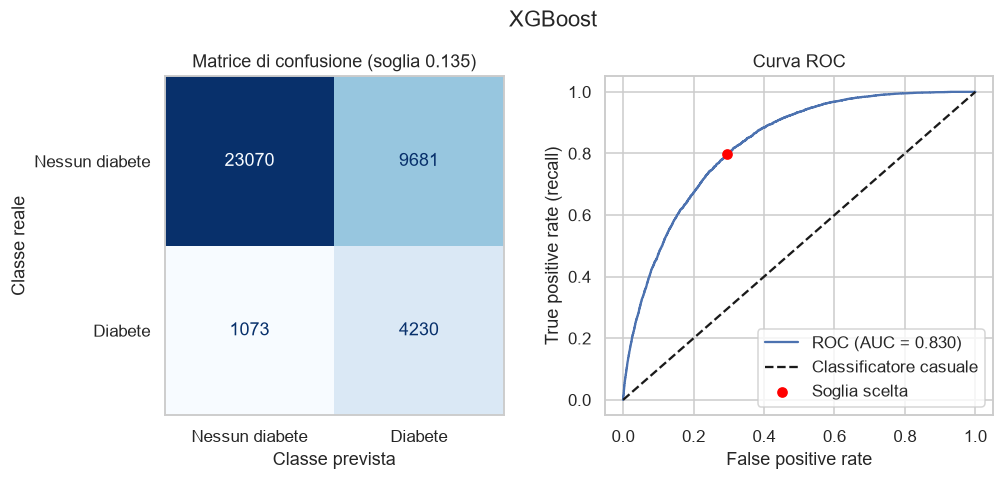

In [15]:
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix,
                             roc_curve)

proba_test = {name: model.predict_proba(X_test)[:, 1]
              for name, model in best_models.items()}


def show_results(name):
    proba = proba_test[name]
    pred = (proba >= thresholds[name]).astype(int)
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    fpr, tpr, _ = roc_curve(y_test, proba)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    ConfusionMatrixDisplay(cm, display_labels=["Nessun diabete", "Diabete"]
                           ).plot(ax=axes[0], cmap="Blues", colorbar=False,
                           values_format="d")
    axes[0].set_title(f"Matrice di confusione (soglia {thresholds[name]:.3f})")
    axes[0].set_xlabel("Classe prevista")
    axes[0].set_ylabel("Classe reale")
    axes[0].grid(False)

    auc = roc_auc_score(y_test, proba)
    axes[1].plot(fpr, tpr, label=f"ROC (AUC = {auc:.3f})")
    axes[1].plot([0, 1], [0, 1], "k--", label="Classificatore casuale")
    axes[1].scatter(fp / (fp + tn), tp / (tp + fn), color="red", zorder=3,
                    label="Soglia scelta")
    axes[1].set_xlabel("False positive rate")
    axes[1].set_ylabel("True positive rate (recall)")
    axes[1].set_title("Curva ROC")
    axes[1].legend(loc="lower right")

    fig.suptitle(name, y=1.03)
    plt.show()

show_results("Regressione logistica")
show_results("Random Forest")
show_results("XGBoost")

Le tre matrici di confusione hanno una struttura molto simile: dei 5.303
malati del test ne vengono individuati **circa 4.200** (4.229 con la
regressione logistica, 4.201 con la Random Forest, 4.230 con XGBoost) e ne
restano **esclusi circa 1.100**. Il prezzo è di **9.700-10.100 persone senza**
diabete segnalate per errore, cioè **più di due falsi positivi** per ogni
malato individuato. Le curve ROC dei tre modelli sono **quasi sovrapposte** e
ben sopra la diagonale del classificatore casuale; il punto della soglia
scelta si trova a un true positive rate di circa 0,80 e a un false
positive rate di circa 0,30.

## Metriche sul test set

In [16]:
rows = []
for name in best_models:
    proba = proba_test[name]
    y_pred = (proba >= thresholds[name]).astype(int)
    rows.append({"Modello": name,
                 "Soglia": thresholds[name],
                 "Precision": precision_score(y_test, y_pred),
                 "Recall": recall_score(y_test, y_pred),
                 "F-measure": f1_score(y_test, y_pred),
                 "Accuracy": accuracy_score(y_test, y_pred),
                 "ROC AUC": roc_auc_score(y_test, proba)})

metrics_test = pd.DataFrame(rows).set_index("Modello")
print(metrics_test.round(3).to_string())

                       Soglia  Precision  Recall  F-measure  Accuracy  ROC AUC
Modello                                                                       
Regressione logistica   0.124      0.296   0.797      0.431     0.707    0.821
Random Forest           0.142      0.300   0.792      0.435     0.714    0.825
XGBoost                 0.135      0.304   0.798      0.440     0.717    0.830


Sul test, con le soglie fissate sul validation, la recall è 0,797 per la
regressione logistica, 0,792 per la Random Forest e 0,798 per XGBoost:
**leggermente sotto l'obiettivo di 0,80**, perché la soglia è stata scelta su
un altro campione, con uno scarto inferiore a un punto percentuale. Precision
(0,296, 0,300 e 0,304), F-measure (0,431, 0,435 e 0,440) e ROC AUC (0,821,
0,825 e 0,830) sono **praticamente uguali a quelle del validation**: le scelte
di modelli e soglie **non si sono adattate al validation**. XGBoost resta il
migliore, con differenze piccole rispetto agli altri due.

# Spiegabilità con SHAP

Per capire su quali informazioni si basano le previsioni usiamo **SHAP**
(SHapley Additive exPlanations) applicato a XGBoost, il modello migliore.
SHAP attribuisce a ogni feature un contributo, il **valore di Shapley**, alla
singola predizione: partendo dal **valore base**, cioè la predizione media del
modello, la somma dei contributi restituisce esattamente la predizione per
quella persona. Per i modelli ad albero l'algoritmo **TreeSHAP** calcola questi
valori in modo esatto ed efficiente.

Il risultato si visualizza con un **waterfall plot**. Per XGBoost i
contributi sono espressi in **log-odds**, la scala su cui il modello somma i
risultati degli alberi: valori **positivi aumentano il rischio** stimato,
valori **negativi lo riducono**. Il valore base, -1,85, corrisponde a una
probabilità del 13,6%, vicina alla prevalenza del diabete.

Analizziamo due persone del test con diabete: una individuata dal modello
e una non individuata.

Probabilità stimata: 0.230 (soglia 0.135)


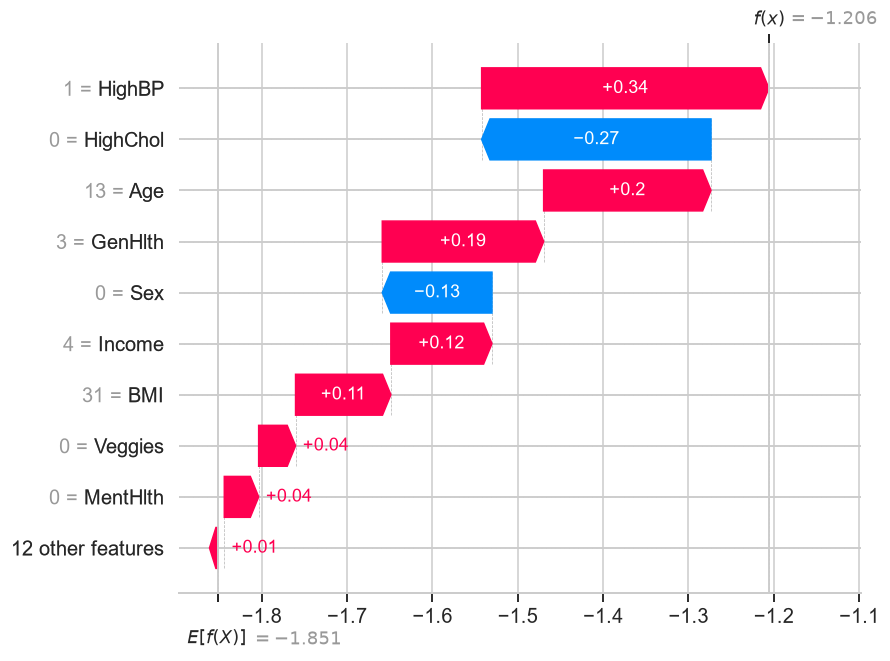

In [17]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")
import shap

model_xgb = best_models["XGBoost"]

# TreeSHAP: algoritmo esatto per modelli ad albero
explainer = shap.TreeExplainer(model_xgb)
shap_values = explainer(X_test)

proba_xgb = proba_test["XGBoost"]
pred_xgb = (proba_xgb >= thresholds["XGBoost"]).astype(int)
y_true = y_test.to_numpy()

# Prima persona con diabete individuata dal modello (vero positivo)
tp = np.where((y_true == 1) & (pred_xgb == 1))[0][0]
print(f"Probabilità stimata: {proba_xgb[tp]:.3f} "
      f"(soglia {thresholds['XGBoost']:.3f})")
shap.plots.waterfall(shap_values[tp])

La prima persona riceve una **probabilità di 0,230**, sopra la soglia di 0,135,
e **viene quindi segnalata**. Il contributo maggiore viene dall'**ipertensione**
(`HighBP` = 1, +0,34), seguita dall'età (`Age` = 13, cioè 80 anni o più,
+0,20), da una salute generale solo "buona" (`GenHlth` = 3, +0,19) e da un
reddito basso (`Income` = 4, +0,12). L'assenza di colesterolo alto (-0,27)
e il sesso femminile (-0,13) riducono invece il rischio stimato.

Probabilità stimata: 0.067 (soglia 0.135)


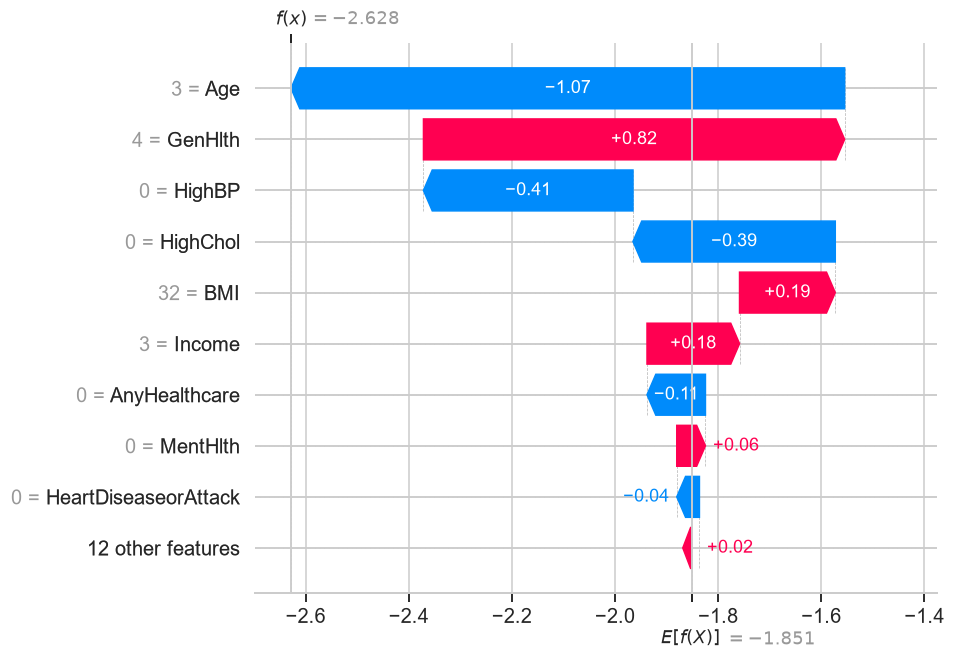

In [18]:
# Prima persona con diabete non individuata dal modello (falso negativo)
fn = np.where((y_true == 1) & (pred_xgb == 0))[0][0]
print(f"Probabilità stimata: {proba_xgb[fn]:.3f} "
      f"(soglia {thresholds['XGBoost']:.3f})")
shap.plots.waterfall(shap_values[fn])

La seconda persona ha il diabete ma riceve una **probabilità di 0,067** e non
viene segnalata. Pesa soprattutto **l'età giovane** (`Age` = 3, cioè 30-34
anni), che da sola abbassa il rischio di 1,07, più di quanto lo alzino la
salute generale "discreta" (`GenHlth` = 4, +0,82), il BMI di 32 (+0,19) e
il reddito basso (+0,18); anche l'assenza di ipertensione e di colesterolo
alto lo riduce (-0,41 e -0,39). Il modello ha appreso che il diabete è
**raro tra i giovani**, e per questo fatica a riconoscere i casi che non
seguono l'andamento tipico.

In entrambi i casi i contributi maggiori vengono da salute generale,
ipertensione, età, colesterolo e BMI, in accordo con la PCA,
in cui la salute generale domina la prima componente. I valori SHAP descrivono però **come ragiona il modello**, non le
cause del diabete: variabili come ipertensione e colesterolo alto sono in
parte **comorbilità o conseguenze** della malattia, e con feature correlate
(come `GenHlth`, `PhysHlth` e `DiffWalk`) il contributo può distribuirsi
tra di esse in modo non univoco.

# Discussione dei risultati

## Confronto con la letteratura

Sul test set i tre modelli raggiungono una ROC AUC di 0,821
(regressione logistica), 0,825 (Random Forest) e 0,830 (XGBoost). Sono
valori **in linea** con Xie et al. (2019), che su dati BRFSS 2014 ottengono
AUC tra 0,72 e 0,79 con un hold-out singolo, e con lo studio di
riproducibilità di **Shechter e Shomron (2026)**, la cui AUC migliore sul
BRFSS 2015 è 0,83. Quest'ultimo lavoro riporta anche una regressione
logistica con AUC 0,82 e recall 0,97, ma con **specificità 0,35**: lo stesso
potere discriminante, con una soglia che segnala quasi tutti.

Risultati molto più alti, come l'accuracy del 98% con KNN di Ullah et al.
(2022), **non sono confrontabili con i nostri**. Una spiegazione plausibile,
**non dimostrata**, è il ricampionamento delle classi combinato con una
suddivisione dei dati non dichiarata nei dettagli, che può far comparire
nel test punti derivati da quelli del training. Nel nostro lavoro il
test **non ha profili in comune con il training** e nessuna scelta è stata
fatta su di esso.

## Cosa mostrano i risultati

I tre modelli sono vicini: la differenza tra regressione logistica e
XGBoost è di circa 0,01 di AUC. Un modello lineare quasi al livello dei
modelli ad albero indica che **il segnale utile è in gran parte lineare** e
che il questionario contiene un'**informazione limitata**: 1.566 profili hanno
etichette discordanti, cioè a parità di risposte l'esito cambia.

Con la recall fissata a 0,80, XGBoost segnala **circa il 37% delle persone** e
tra queste **il 30% ha il diabete**, più del doppio della prevalenza (13,9%).
Il modello è quindi utile per **dare priorità** a chi inviare a esami di
conferma, ma **non come strumento diagnostico**: per ogni malato individuato
si segnalano **circa 2,3 persone sane**.

## Controlli di plausibilità

Un'**AUC superiore a 0,90** su questo dataset sarebbe stata un segnale di
**possibile leakage**; i nostri valori restano nell'intervallo atteso. Le
prestazioni di XGBoost sono **coerenti tra cross-validation** (0,831),
validation (0,829) e test (0,830), e la recall sul test (0,792-0,798) è
quasi uguale all'obiettivo fissato sul validation: le scelte di modelli e
soglie non si sono adattate al validation set.

# Limiti

- **Dati auto-riportati e trasversali.** Le risposte sono dichiarazioni
  telefoniche, soggette a errori di ricordo e di desiderabilità sociale, e
  fotografano un solo istante: i modelli colgono **associazioni, non cause** né
  evoluzioni nel tempo. Il target è una **diagnosi già ricevuta**, quindi il
  modello riconosce chi ha già l'etichetta e non prevede nuovi casi.
- **Definizione del target.** La documentazione descrive la classe positiva
  come "prediabete o diabete" ma non spiega come sia stato codificato il
  prediabete: i prediabetici **potrebbero essere nella classe negativa**.
  Non è verificabile sui dati.
- **Rappresentatività.** Il file non contiene i **pesi di campionamento** del
  BRFSS e conserva solo le risposte complete (**57,5%** di quelle originali),
  per cui la prevalenza del 13,9% non coincide con quella della popolazione
  e il campione può essere distorto.
- **Variabili che sono anche conseguenze.** Ipertensione, colesterolo alto,
  cardiopatie e difficoltà motorie sono **in parte effetti** del
  diabete. Altre riguardano l'accesso alle cure, come `CholCheck`, e
  possono riflettere il fatto che chi ha il diabete viene controllato più
  spesso: vanno lette come associazioni. Sesso, reddito e istruzione sono variabili
  sensibili: la loro presenza tra i predittori **richiede cautela**.
- **Rumore nelle etichette.** In 1.566 profili le risposte coincidono ma
  l'esito è diverso: è una parte di **errore irriducibile** che limita le
  prestazioni di qualsiasi modello.
- **Scelte metodologiche.** Le variabili ordinali sono trattate come numeri;
  la recall minima dell'80% è **un'assunzione**, non un valore ottimizzato; la
  **calibrazione delle probabilità** non è stata verificata; alcuni
  iperparametri sono ai bordi delle griglie, che sono state mantenute
  contenute per ridurre i tempi di calcolo.
- **Validazione.** Tutte le valutazioni provengono da **un unico anno** di
  indagine e da un'unica suddivisione dei dati: non c'è una validazione su
  un'altra coorte o su un anno diverso.

# Conclusioni

Il lavoro mostra che, a partire dalle sole risposte a un questionario di
salute, è possibile costruire un modello capace di ordinare le persone per
rischio di diabete in modo sensato, ma **non di diagnosticarlo**. I tre
classificatori confrontati si comportano in modo molto simile, segno che
il limite sta più nell'**informazione disponibile** che nella complessità del
modello: aggiungere potenza di calcolo o algoritmi più sofisticati
difficilmente cambierebbe il quadro.

Un aspetto importante è il modo in cui sono stati ottenuti
questi risultati. Suddividere i dati senza far comparire gli stessi profili
in più insiemi e scegliere la soglia lontano dal test rende le prestazioni
più modeste di alcune riportate in letteratura, ma **più credibili** e
coerenti tra le diverse fasi di valutazione. L'analisi con SHAP indica
inoltre, nei casi esaminati, che il modello si appoggia su **fattori clinicamente plausibili**,
anche se resta una descrizione di come il modello ragiona e non delle
cause della malattia.

In uno screening il valore di uno strumento di questo tipo sta nel dare
**priorità a chi sottoporre a esami di conferma**. Per andare oltre sarebbero
necessarie informazioni più ricche, per esempio **misure cliniche**, e una
verifica su **altre coorti** e su anni diversi.

# Riferimenti

- CDC Diabetes Health Indicators, UCI Machine Learning Repository,
  DOI 10.24432/C53919.
- Xie Z., Nikolayeva O., Luo J., Li D. (2019). *Building risk prediction
  models for type 2 diabetes using machine learning techniques*.
  Preventing Chronic Disease, 16, 190109.
- Ullah Z., Saleem F., Jamjoom M., Fakieh B., Kateb F., Ali A. M.,
  Shah B. (2022). *Detecting high-risk factors and early diagnosis of
  diabetes using machine learning methods*. Computational Intelligence
  and Neuroscience, 2022, 2557795, DOI 10.1155/2022/2557795.
- Shechter S., Shomron N. (2026). *Machine learning for diabetes screening:
  insights from the Behavioral Risk Factor Surveillance System and Pima
  Indians Diabetes Databases*. Journal of Scientific Innovation in
  Medicine, 9(1), DOI 10.29024/jsim.283.